# 09 · Quality assurance and dataset fit

Verify artifact integrity separately from model and production readiness.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
import wave
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

### Math for the next code block — audio round-trip convention

The QA reader uses the same convention as preprocessing: $x=q/32768$ for decoding and clipped $q=\operatorname{round}(32768x)$ for encoding.

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as wav:
        meta = {"sample_rate": wav.getframerate(), "channels": wav.getnchannels(),
                "sample_width": wav.getsampwidth(), "frames": wav.getnframes()}
        if wav.getcomptype() != "NONE" or meta["sample_width"] != 2:
            raise ValueError("Only uncompressed PCM16 WAV is supported")
        pcm = wav.readframes(meta["frames"])
    if not meta["frames"] or len(pcm) != meta["frames"] * meta["channels"] * 2:
        raise ValueError("Empty or truncated PCM")
    audio = np.frombuffer(pcm, dtype="<i2").reshape(-1, meta["channels"]).astype(np.float32) / 32768
    meta["pcm_sha256"] = hashlib.sha256(pcm).hexdigest()
    return audio, meta

def write_audio(path, audio, rate):
    path.parent.mkdir(parents=True, exist_ok=True)
    pcm = np.clip(np.rint(np.asarray(audio) * 32768), -32768, 32767).astype("<i2")
    with wave.open(str(path), "wb") as wav:
        wav.setnchannels(1); wav.setsampwidth(2); wav.setframerate(rate)
        wav.writeframes(pcm.tobytes())

## Load final-stage artifacts

In [4]:
splits=("train","validation","test")
originals=load_manifest("05_standardized.jsonl")
rows=load_manifest("08_normalized.jsonl")
metadata=json.loads((out/"08_normalized/statistics_provenance.json").read_text())
stats=np.load(out/"08_normalized/training_statistics.npz")

## Structural and leakage checks

### Math for the next code block — split integrity

Each split must contain both classes:

$$n_{s,+}>0\quad\land\quad n_{s,-}>0.$$

Speaker-ID and PCM-hash sets must be pairwise disjoint:

$$S_i\cap S_j=\varnothing\quad\text{for every }i\ne j.$$

In [5]:
checks={}
summary={split:{"clips":len([r for r in originals if r["split"]==split]),
                "speakers":len({r["speaker_id"] for r in originals if r["split"]==split}),
                "positive":sum(r["is_keyword"] for r in originals if r["split"]==split),
                "negative":sum(not r["is_keyword"] for r in originals if r["split"]==split)} for split in splits}
checks["every_split_has_both_classes"]=all(v["positive"] and v["negative"] for v in summary.values())
for field in ("speaker_id","pcm_sha256"):
    checks[f"zero_cross_split_{field}_overlap"]=all(not ({r[field] for r in originals if r["split"]==a}&{r[field] for r in originals if r["split"]==b})
                                                       for i,a in enumerate(splits) for b in splits[i+1:])
checks["original_pcm_unique"]=len({r["pcm_sha256"] for r in originals})==len(originals)

In [6]:
def file_sha256(path):
    digest=hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda:stream.read(1024*1024),b""): digest.update(block)
    return digest.hexdigest()

checks["raw_files_unchanged"]=all(file_sha256(root/r["raw_path"])==r["raw_sha256"] for r in originals)
checks["augmentation_train_only"]=all(r["split"]=="train" for r in rows if r["is_augmented"])
parent_ids={r["id"] for r in originals if r["split"]=="train"}
checks["augmentation_parent_in_training"]=all(r["parent_id"] in parent_ids for r in rows if r["is_augmented"])
checks["normalization_fit_only_original_training"]=set(metadata["fit_ids"])==parent_ids

## Audio, feature, and normalization checks

### Math for the next code block — shape and normalization checks

For $N$ audio samples, expected frames are

$$T=1+\left\lfloor\frac{N-W}{H}\right\rfloor,$$

so raw and normalized feature arrays must both have shape $T\times M$. QA also verifies

$$Z\approx(F-\mu)/\sigma$$

within absolute and relative tolerance $10^{-6}$. Across original training frames it requires

$$\max_r|\bar z_r|<10^{-5},\qquad\max_r|s_r-1|<10^{-5}.$$

In [7]:
checks.update(audio_format_and_length=True,feature_shapes_and_finite_values=True,normalization_matches_saved_statistics=True)
count=0
summed=np.zeros(cfg["mel_bands"])
squared=summed.copy()
fit_ids=set(metadata["fit_ids"])
for record in rows:
    audio,meta=read_audio(root/record["audio_path"])
    features=np.load(root/record["feature_path"])
    normalized=np.load(root/record["normalized_path"])
    expected=1+(len(audio)-cfg["window_samples"])//cfg["hop_samples"]
    checks["audio_format_and_length"] &= meta["sample_rate"]==cfg["sample_rate"] and meta["channels"]==1 and len(audio)==record["standardized_samples"]
    checks["feature_shapes_and_finite_values"] &= features.shape==normalized.shape==(expected,cfg["mel_bands"]) and np.isfinite(features).all() and np.isfinite(normalized).all()
    checks["normalization_matches_saved_statistics"] &= np.allclose(normalized,(features-stats["mean"])/stats["std"],atol=1e-6,rtol=1e-6)
    if record["id"] in fit_ids:
        values=normalized.astype(np.float64)
        count+=len(values)
        summed+=values.sum(0)
        squared+=(values*values).sum(0)
train_mean=summed/count; train_std=np.sqrt(np.maximum(squared/count-train_mean**2,0))
checks["training_normalized_mean_near_zero"]=np.max(np.abs(train_mean))<1e-5
checks["training_normalized_std_near_one"]=np.max(np.abs(train_std-1))<1e-5

## Streaming equivalence

The same causal transform is repeated here so the production-relevant batch/stream check is visible in this notebook.

### Math for the next code block — independent feature reconstruction

QA repeats the notebook-07 transform rather than trusting saved output:

$$F[t,r]=\ln\!\left(\max\!\left(\sum_k\frac{|\operatorname{DFT}(x_t\odot w)[k]|^2}{K}H_r(f_k),\epsilon\right)\right).$$

Here $x_t$ is a complete causal frame, $w$ is the periodic Hann window, $H_r$ is Mel filter $r$, and $\epsilon=10^{-10}$.

In [8]:
class LogMel:
    def __init__(self,cfg):
        self.cfg=cfg; self.window=np.hanning(cfg["window_samples"]+1)[:-1].astype(np.float32)
        hz_to_mel=lambda f:2595*np.log10(1+np.asarray(f)/700)
        mel_to_hz=lambda m:700*(10**(np.asarray(m)/2595)-1)
        edges=mel_to_hz(np.linspace(hz_to_mel(cfg["mel_min_hz"]),hz_to_mel(cfg["mel_max_hz"]),cfg["mel_bands"]+2))
        frequency=np.fft.rfftfreq(cfg["fft_size"],1/cfg["sample_rate"])
        left=(frequency[None,:]-edges[:-2,None])/(edges[1:-1,None]-edges[:-2,None])
        right=(edges[2:,None]-frequency[None,:])/(edges[2:,None]-edges[1:-1,None])
        self.filters=np.maximum(0,np.minimum(left,right)).astype(np.float32)
        if np.any(self.filters.sum(axis=1)==0): raise ValueError("Empty Mel filter")

    def frames(self,frames):
        spectrum=np.fft.rfft(frames*self.window,n=self.cfg["fft_size"],axis=-1)
        power=np.abs(spectrum)**2/self.cfg["fft_size"]
        return np.log(np.maximum(power@self.filters.T,self.cfg["log_floor"])).astype(np.float32)

    def __call__(self,signal):
        size,hop=self.cfg["window_samples"],self.cfg["hop_samples"]
        if len(signal)<size: return np.empty((0,self.cfg["mel_bands"]),dtype=np.float32)
        frames=np.lib.stride_tricks.sliding_window_view(signal,size)[::hop]
        return self.frames(frames)

### Math for the next code block — causality invariant

For any chunk sequence whose concatenation is $x$, the intended invariant is

$$F_{\mathrm{stream}}(c_1,c_2,\ldots,c_J)=F_{\mathrm{batch}}(x)$$

for every complete frame. Unfinished samples remain buffered and are not padded with future values.

In [9]:
class StreamingLogMel:
    # Emit completed windows only; retain overlap without future padding.
    def __init__(self,extractor):
        self.extractor=extractor; self.pending=np.empty(0,dtype=np.float32)
    def push(self,chunk):
        self.pending=np.concatenate((self.pending,np.asarray(chunk,dtype=np.float32)))
        features=self.extractor(self.pending)
        self.pending=self.pending[len(features)*self.extractor.cfg["hop_samples"]:]
        return features

### Math for the next code block — numerical equivalence error

For each checked recording, QA measures

$$e=\max_{t,r}|F_{\mathrm{stream}}[t,r]-F_{\mathrm{batch}}[t,r]|.$$

The check passes when $\max e<10^{-5}$. Random chunk sizes exercise frame boundaries that do not align with microphone callbacks.

In [10]:
extractor=LogMel(cfg)
rng=np.random.default_rng(7)
errors=[]
selected=sorted(originals,key=lambda r:(r["duration_seconds"],r["id"]))
selected=selected[:3]+selected[len(selected)//2:len(selected)//2+3]+selected[-3:]
for record in selected:
    audio,_=read_audio(root/record["audio_path"])
    signal=audio[:,0]
    stream=StreamingLogMel(extractor)
    chunks=[]
    offset=0
    while offset<len(signal):
        size=int(rng.integers(1,1200))
        chunks.append(stream.push(signal[offset:offset+size]))
        offset+=size
    errors.append(float(np.max(np.abs(np.concatenate(chunks)-extractor(signal)))))
checks["chunked_features_match_causal_batch"]=max(errors)<1e-5

## Save the acceptance report and model-input manifests

### Math for the next code block — acceptance rule

If checks are Boolean values $c_1,\ldots,c_J$, preprocessing passes only when

$$C_{\mathrm{pass}}=\bigwedge_{j=1}^{J}c_j=\text{True}.$$

This logical conjunction establishes data-pipeline integrity. It does not imply that the dataset supplies HMM labels or production evaluation coverage.

In [11]:
qa={"preprocessing_pass":bool(all(checks.values())),"checks":{k:bool(v) for k,v in checks.items()},"splits":summary,
    "original_clips":len(originals),"augmented_clips":sum(r["is_augmented"] for r in rows),
    "max_streaming_feature_error":max(errors),"max_training_normalized_mean_abs":float(np.max(np.abs(train_mean))),
    "max_training_normalized_std_error":float(np.max(np.abs(train_std-1)),),
    "phonetic_hmm_training_ready":False,"production_evaluation_ready":False,
    "missing":["Verified speech/keyword boundaries","Phonetic-state alignment labels","Continuous background and phonetic-confusion coverage","Mobile/far-field evaluation","Manual audio/label review"],
    "fit_verdict":"Useful for a stop-vs-other-word mechanics experiment; insufficient for supervised phonetic DNN-HMM training or production claims."}
save_json(reports/"qa.json",qa); save_manifest("09_final_manifest.jsonl",rows)
for split in splits: save_manifest(f"09_final/{split}.jsonl",[r for r in rows if r["split"]==split])
if not qa["preprocessing_pass"]: raise RuntimeError("Preprocessing QA failed")

In [12]:
display([{"check":name,"result":"PASS" if passed else "FAIL"} for name,passed in checks.items()])
display({"preprocessing_pass":qa["preprocessing_pass"],"phonetic_hmm_training_ready":False,
         "production_evaluation_ready":False,"missing":qa["missing"]})

[{'check': 'every_split_has_both_classes', 'result': 'PASS'},
 {'check': 'zero_cross_split_speaker_id_overlap', 'result': 'PASS'},
 {'check': 'zero_cross_split_pcm_sha256_overlap', 'result': 'PASS'},
 {'check': 'original_pcm_unique', 'result': 'PASS'},
 {'check': 'raw_files_unchanged', 'result': 'PASS'},
 {'check': 'augmentation_train_only', 'result': 'PASS'},
 {'check': 'augmentation_parent_in_training', 'result': 'PASS'},
 {'check': 'normalization_fit_only_original_training', 'result': 'PASS'},
 {'check': 'audio_format_and_length', 'result': 'PASS'},
 {'check': 'feature_shapes_and_finite_values', 'result': 'PASS'},
 {'check': 'normalization_matches_saved_statistics', 'result': 'PASS'},
 {'check': 'training_normalized_mean_near_zero', 'result': 'PASS'},
 {'check': 'training_normalized_std_near_one', 'result': 'PASS'},
 {'check': 'chunked_features_match_causal_batch', 'result': 'PASS'}]

{'preprocessing_pass': True,
 'phonetic_hmm_training_ready': False,
 'production_evaluation_ready': False,
 'missing': ['Verified speech/keyword boundaries',
  'Phonetic-state alignment labels',
  'Continuous background and phonetic-confusion coverage',
  'Mobile/far-field evaluation',
  'Manual audio/label review']}

## Readiness view

A passing pipeline does not supply missing labels or production evidence.

In [13]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

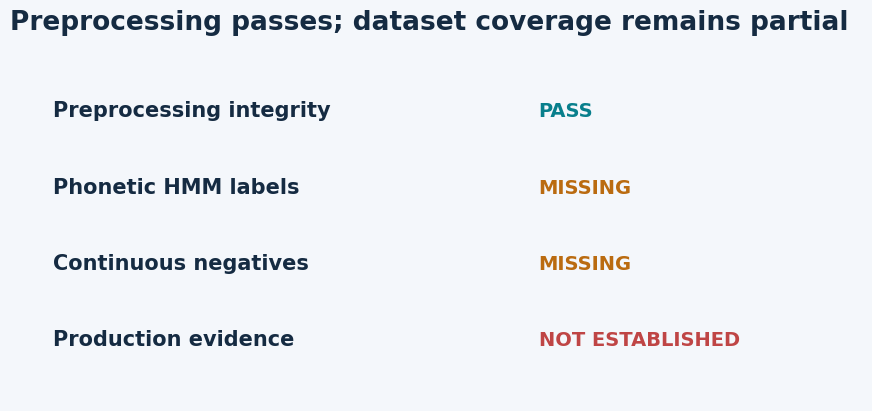

In [14]:
items=[("Preprocessing integrity","PASS",TEAL),("Phonetic HMM labels","MISSING",AMBER),
       ("Continuous negatives","MISSING",AMBER),("Production evidence","NOT ESTABLISHED",RED)]
fig,ax=plt.subplots(figsize=(11,4.5))
ax.axis("off")
for i,(label,status,color) in enumerate(items):
    y=.82-i*.22
    ax.text(.05,y,label,fontsize=15,weight="bold",color=INK,transform=ax.transAxes)
    ax.text(.62,y,status,fontsize=14,weight="bold",color=color,transform=ax.transAxes)
ax.set_title("Preprocessing passes; dataset coverage remains partial",loc="left",fontsize=19,weight="bold",color=INK,pad=18)
finish_figure(fig,"09_readiness")

## Does this dataset match the wake-word problem?

| Requirement | Verdict |
|---|---|
| `stop` versus other isolated words | Suitable starter |
| Phonetic-state DNN–HMM supervision | Missing alignments |
| Custom wake phrase | Not present |
| False accepts per hour | Continuous negatives required |
| Mobile/far-field robustness | Representative evaluation required |

The next experiment should create and review boundaries or phonetic alignments before fitting a DNN–HMM. Keep test data fixed and independent of model predictions.

In [15]:
report = (f"# Preprocessing report · {cfg['run_name']}\n\n"
          f"**Preprocessing QA: {'PASS' if qa['preprocessing_pass'] else 'FAIL'}.**\n\n"
          f"Retained {qa['original_clips']:,} unique recordings and generated {qa['augmented_clips']:,} training-only variants. "
          f"Maximum streaming-versus-batch feature error: {qa['max_streaming_feature_error']:.3g}.\n\n"
          "The data is useful for a `stop` versus other-word mechanics experiment. It is not ready for phonetic DNN–HMM supervision or production evaluation because alignments, continuous negatives, mobile/far-field tests, and manual review are missing.\n\n"
          "![Raw inventory](figures/01_raw_inventory.png)\n\n![Readiness](figures/09_readiness.png)\n")
(reports/"report.md").write_text(report)

532